# Example 2: Manually tagged elements

The drawing from papermodels' Example 2, where `FB2.5`, `FB1.14` and `CB0.10` were tagged by
hand in the PDF and the other elements were tagged around them. loadtracer uses the tags that
papermodels assigns, so the manually tagged elements appear in the results under their own names.

**Note:** papermodels 0.21 keeps the manual tags `FB1.14` and `CB0.10`, but names the beam that
the PDF tags `FB2.5` (page 2) `FB2.0`. That is a papermodels issue; loadtracer reports whatever
tags the graph has.

In [1]:
%matplotlib inline
import sys
import warnings
from decimal import Decimal

import pandas as pd
from papermodels.datatypes.geometry_graph import GeometryGraph
from papermodels.datatypes.joist_models import JoistArrayModel
from loadtracer.load_tracer import LoadTracer

sys.path.insert(0, "..")
from helpers import (
    bottom_members,
    compare_modes,
    load_check,
    load_table,
    occupancies_in,
    quietly,
    reaction_table,
)

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_rows = 40

## 1. Build the graph (papermodels)

In [2]:
pdf_path = "sketch_to_scale-w_manual_tag.pdf"

In [3]:
graph = GeometryGraph.from_pdf_file(pdf_path, scale=Decimal(1 / 72 * 4))
graph.assign_collector_behaviour(JoistArrayModel, spacing=1.0)

/home/engineering/papermodels/src/papermodels/datatypes/joist_models.py:237: UserWarning: Joist array J2.0: support WT2.0 is a polygon with a point reaction type; the joists bear on it along its long axis. If it is a wall, add 'Reaction Type: Linear' to its legend entry.
  warnings.warn(msg)


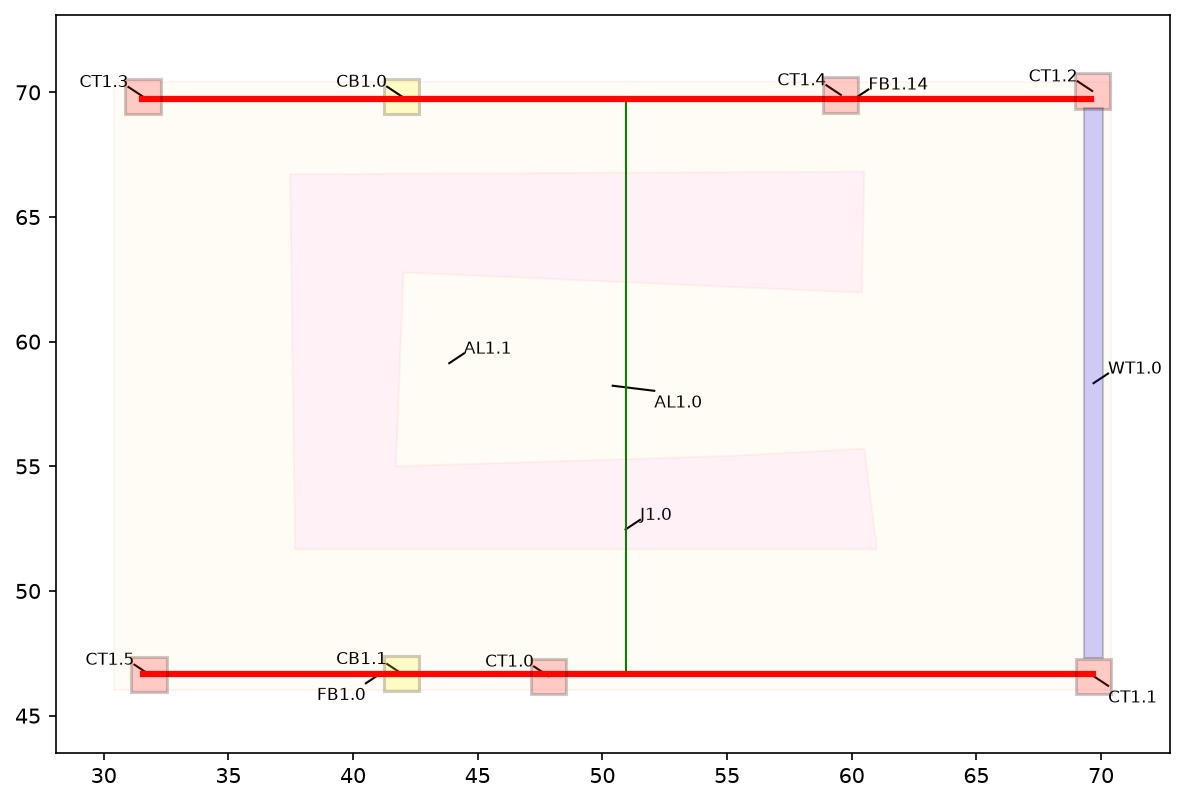

In [4]:
graph.plot_annotations(1)

## 2. Occupancies

loadtracer needs the loads of each occupancy in the drawing, as pressures by load case.
These are the occupancies that the loading areas use:

In [5]:
occupancies_in(graph)

['big stuff', 'residential', 'roof']

The drawing is in feet, so these pressures (psf) give loads in lb/ft and lb.

In [6]:
occupancies = {
    "big stuff": {"D": 50.0, "L": 100.0},
    "residential": {"D": 15.0, "L": 40.0},
    "roof": {"D": 20.0, "S": 35.0},
}

## 3. Run loadtracer

Every element is analysed from the top of the graph down. Only the graph and the occupancies
are needed; element heights and floor elevations are not inputs. `artifacts/` receives the
analysis models (`models.json`) and the reactions (`reaction_forces.json`).

In [7]:
lt = LoadTracer(geometry_graph=graph, occupancies=occupancies)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    quietly(lt.execute_analyses, artifacts_dir="artifacts")

print(f"{len(lt.reactions)} members analysed, {len(lt.errors)} errors")
for w in caught:
    print(f"{type(w.message).__name__}: {w.message}")

55 members analysed, 0 errors


All of the load applied to the building reaches the bottom of the graph:

In [8]:
load_check(lt)

,applied,at the bottom
D,"8,666.48","8,666.48"
S,"6,563.13","6,563.13"
L,"11,832.06","11,832.06"


`lt.issues` lists input that loadtracer corrected so that the rundown could continue
(for example, load drawn past the end of a member, which is moved to the member end):

In [9]:
{tag: issues for tag, issues in lt.issues.items()}

{}

## 4. One member, end to end: `FB1.14`

`FB1.14` is one of the manually tagged beams. It is continuous over three supports and
carries the `J1.0` joist array.

In [10]:
pd.DataFrame(lt.converted_joist_loads("FB1.14"))

,member,array,joists,case,dir,profile,start_loc,end_loc,w_start,w_end,total,max_min_ratio,occupancy,pressure,trib_width_start,trib_width_end,approximate
0,FB1.14,J1.0,20,D,FY,variable,0.12,18.27,141.11,141.11,"2,562.36",3.04,big stuff,50.00,2.82,2.82,True
1,FB1.14,J1.0,20,L,FY,variable,0.12,18.27,337.30,337.30,"6,124.63",2.53,big stuff,100.00,3.37,3.37,True


The loads on `FB1.14` after expansion, by load case:

In [11]:
load_table(lt, "FB1.14")

,kind,source,case,start,end,w_start / P,w_end,total,profile
0,point,CB1.0,D,4.98,4.98,"1,196.47",NaN,"1,196.47",
1,point,CB1.0,S,4.98,4.98,"2,093.82",NaN,"2,093.82",
2,distributed,J1.0,D,0.12,18.27,141.11,141.11,"2,562.36",variable
3,distributed,J1.0,L,0.12,18.27,337.30,337.30,"6,124.63",variable


The loads in the Pynite model of `FB1.14`:

In [12]:
member = lt.models["FB1.14"]["members"]["FB1.14"]
pd.DataFrame(member["DistLoads"] + member["PtLoads"])

,0,1,2,3,4,5,6
0,FY,141.11,141.11,0.12,18.27,D,False
1,FY,337.30,337.30,0.12,18.27,L,False
2,FY,"1,196.47",4.98,D,NaN,NaN,None
3,FY,"2,093.82",4.98,S,NaN,NaN,None


The reactions of `FB1.14` (positive downwards on the supports):

In [13]:
reaction_table(lt, ["FB1.14"])

D        L        S
member support                           
FB1.14 0       1,361.71 1,791.11 1,071.64
       1       2,952.78 4,728.17 1,705.66
       2        -555.67  -394.64  -683.48

The manually tagged elements that papermodels kept, under their own tags:

In [14]:
reaction_table(lt, ["FB1.14", "CB0.10"])

D        L        S
member support                           
FB1.14 0       1,361.71 1,791.11 1,071.64
       1       2,952.78 4,728.17 1,705.66
       2        -555.67  -394.64  -683.48
CB0.10 0       2,952.78 4,728.17 1,705.66

The PDF's `FB2.5` is not in the graph; the level 2 beams are:

In [15]:
sorted(tag for tag in lt.reactions if tag.startswith("FB2"))

['FB2.0']

## 5. Joist loads as point loads or distributed loads

With `joist_loads="point"` each joist reaction is applied as a point load, which is the most
detailed representation. The total load is the same either way. Individual reactions are the
same for uniform joist reactions and differ more the more the joist reactions vary; arrays that
vary by 2:1 or more are listed in the warnings in section 3. For those, check the point load
results.

In [16]:
lt_point = LoadTracer(geometry_graph=graph, occupancies=occupancies, joist_loads="point")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    quietly(lt_point.execute_analyses)

pd.concat({"point": load_check(lt_point)["at the bottom"], "distributed": load_check(lt)["at the bottom"]}, axis=1)

,point,distributed
D,"8,666.48","8,666.48"
S,"6,563.13","6,563.13"
L,"11,832.06","11,832.06"


In [17]:
compare_modes(lt_point, lt, ["FB1.14"])

point                   distributed                    \
                      D        L        S           D        L        S   
member support                                                            
FB1.14 0       1,404.01 1,876.25 1,071.59    1,361.71 1,791.11 1,071.64   
       1       3,140.38 5,101.49 1,705.58    2,952.78 4,728.17 1,705.66   
       2        -785.61  -853.11  -683.45     -555.67  -394.64  -683.48   

               difference                
                        D       L     S  
member support                           
FB1.14 0           -42.29  -85.15  0.05  
       1          -187.59 -373.32  0.08  
       2           229.95  458.47 -0.03

The `J1.0` joists carry the heavier "big stuff" occupancy over part of `FB1.14`, so their
reactions vary by up to 3:1 (see the `JoistLoadVariabilityWarning` in section 3). As a uniform
load, that concentration is spread along the beam, which moves load from the interior support
to the ends. Here, the point load results are the ones to use.

## 6. Reactions at the bottom

The loads delivered to the elements at the bottom of the graph (the foundation):

In [18]:
reaction_table(lt, bottom_members(lt))

,,D,S,L
member,support,,,
WB0.0,0,"1,357.43","2,375.49",0.00
CB0.2,0,-555.67,-683.48,-394.64
CB0.4,0,"1,361.71","1,071.64","1,791.11"
CB0.10,0,"2,952.78","1,705.66","4,728.17"
CB0.0,0,"2,425.06","1,615.36","3,642.06"
CB0.1,0,469.33,-123.20,"1,308.75"
CB0.3,0,655.83,601.65,756.62
